# ExplainIDS: exploratory analysis of corrected CIC-IDS2017

**B4 · reproducible seed 42 · local data only.** Select the repository's `.venv-ml` Python kernel and use **Restart & Run All** from either the repository root or `notebooks/`. Required packages are pandas, numpy, pyarrow, scikit-learn, matplotlib and IPython; seaborn is unnecessary.

The only input is `data/processed/cicids2017.parquet`; the optional profile supplies historical raw/cleaned counts. Full-population counts and feature-quality statistics are kept separate from sampled plots. Every figure is displayed inline and saved under `notebooks/figures/eda_*.png` at 150 dpi; no flow records, identifiers, fitted models or datasets are exported. Feature rankings are exploratory: repeat supervised selection and preprocessing on training data alone before reporting held-out model results.


In [1]:
%matplotlib inline
import gc
import re
import sys
import time
from pathlib import Path

import numpy as np
import pandas as pd
import pyarrow as pa
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from sklearn.decomposition import PCA
from sklearn.feature_selection import mutual_info_classif
from sklearn.preprocessing import StandardScaler

START = time.perf_counter()
SEED = 42
np.random.seed(SEED)
ROOT = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / 'src/ids/data.py').exists()), None)
if ROOT is None:
    raise FileNotFoundError('Open this notebook from the ExplainIDS repository.')
sys.path.insert(0, str(ROOT / 'src'))
from ids.data import BENIGN, LABEL_COL, canonical_label, clean, feature_columns, stratified_sample

DATA = ROOT / 'data/processed/cicids2017.parquet'
FIGURES = ROOT / 'notebooks/figures'
FIGURES.mkdir(parents=True, exist_ok=True)
if not DATA.exists():
    raise FileNotFoundError(f'Build the processed input first: {DATA.relative_to(ROOT)}')
plt.style.use('default')
BLUE = 'tab:blue'
SAVED_FIGURES = []

def save_figure(fig, suffix: str) -> None:
    """Save one report-ready PNG and display the same figure inline."""
    path = FIGURES / f'eda_{suffix}.png'
    fig.savefig(path, dpi=150, bbox_inches='tight', facecolor='white')
    display(fig)
    plt.close(fig)
    SAVED_FIGURES.append(path.name)

parquet = pq.ParquetFile(DATA)
schema = parquet.schema_arrow
# Use the repository's feature exclusion policy, never hard-code model features.
FEATURES = feature_columns(pd.DataFrame(columns=schema.names))
assert LABEL_COL in schema.names and FEATURES
assert all(pa.types.is_floating(schema.field(c).type) or pa.types.is_integer(schema.field(c).type)
           for c in FEATURES), 'Expected numeric features from scripts/build_processed.py.'
META_COLUMNS = [LABEL_COL] + (['source_file'] if 'source_file' in schema.names else ['Timestamp'])
meta = pd.read_parquet(DATA, columns=META_COLUMNS)
label_map = {label: canonical_label(label) for label in meta[LABEL_COL].unique()}
meta[LABEL_COL] = meta[LABEL_COL].map(label_map).astype('category')
if 'source_file' in meta:
    meta['source_file'] = meta['source_file'].astype('category')
N = len(meta)
assert N == parquet.metadata.num_rows
print(f'Python {sys.version.split()[0]} | pandas {pd.__version__} | seed {SEED}')
print(f'Projected metadata: {N:,} rows; numeric features will be read one column at a time.')


Python 3.12.9 | pandas 3.1.0 | seed 42
Projected metadata: 1,836,599 rows; numeric features will be read one column at a time.


## 1. Dataset overview

The row count and feature count below describe the processed Parquet, while memory figures distinguish disk size, projected metadata and the hypothetical full numeric matrix. The profile's raw-to-cleaned reduction combines invalid-row removal and deduplication, so these causes cannot be separated from the saved profile. The build script cleans each source file and then deduplicates **globally** on the stored float32 features (`ids.data.dedup_global`), dropping vectors seen with conflicting labels, so no feature vector can appear in two splits. The profile cleaned at float64 precision, so small count differences from it are expected.


In [2]:
numeric_bytes = N * sum(schema.field(c).type.bit_width // 8 for c in FEATURES)
meta_bytes = int(meta.memory_usage(index=True, deep=True).sum())
overview = pd.DataFrame({
    'item': ['Processed rows', 'Numeric model features', 'Stored columns',
             'Parquet on disk (MiB)', 'Metadata in memory (MiB, categorical labels/source)',
             'Full numeric matrix estimate (MiB, not loaded together)'],
    'value': [N, len(FEATURES), len(schema.names), DATA.stat().st_size / 2**20,
              meta_bytes / 2**20, numeric_bytes / 2**20],
})
display(overview)
excluded = [c for c in schema.names if c not in FEATURES]
print('Excluded from all feature analyses:', ', '.join(excluded))

profile_path = ROOT / 'docs/results/profile_cicids2017.md'
profile_text = profile_path.read_text(encoding='utf-8') if profile_path.exists() else ''
raw_match = re.search(r'^rows:\s*([\d,]+)', profile_text, flags=re.M)
clean_match = re.search(r'after clean:\s*([\d,]+)', profile_text)
raw_count = int(raw_match[1].replace(',', '')) if raw_match else None
profile_clean = int(clean_match[1].replace(',', '')) if clean_match else None
if raw_count is not None:
    rows_removed = raw_count - N
    display(pd.DataFrame([
        {'stage': 'Historical raw profile', 'rows': raw_count, 'removed_vs_raw': 0},
        {'stage': 'Current processed Parquet (global dedup)', 'rows': N,
         'removed_vs_raw': rows_removed},
        *([{'stage': 'Historical profile (global cleaning)', 'rows': profile_clean,
            'removed_vs_raw': raw_count - profile_clean}] if profile_clean is not None else []),
    ]))
    display(Markdown(f'The current file has **{rows_removed:,} fewer rows '
                     f'({rows_removed / raw_count:.2%})** than the historical raw input.'))
    if profile_clean is not None:
        display(Markdown(f'The Parquet has **{N - profile_clean:+,} rows** relative to the '
                         'globally cleaned profile. The Parquet is deduplicated on float32 values and drops '
                         'vectors with conflicting labels, while the profile compared float64 values.'))
else:
    rows_removed = None
    print('Raw count unavailable in the optional profile; removal count cannot be inferred.')


,item,value
0,Processed rows,1.836599e+06
1,Numeric model features,8.300000e+01
2,Stored columns,8.900000e+01
3,Parquet on disk (MiB),2.557090e+02
4,"Metadata in memory (MiB, categorical labels/so...",3.503506e+00
5,"Full numeric matrix estimate (MiB, not loaded ...",5.815037e+02


Excluded from all feature analyses: Src IP, Dst IP, Src Port, Timestamp, source_file, Label


,stage,rows,removed_vs_raw
0,Historical raw profile,2099976,0
1,Current processed Parquet (global dedup),1836599,263377
2,Historical profile (global cleaning),1836977,262999


The current file has **263,377 fewer rows (12.54%)** than the historical raw input.

The Parquet has **-378 rows** relative to the globally cleaned profile. The Parquet is deduplicated on float32 values and drops vectors with conflicting labels, while the profile compared float64 values.

## 2. Class distribution

Counts and percentages use every processed flow and canonical labels from `ids.data`, including its attempted-attack-to-BENIGN policy. Heartbleed, Infiltration and Web-SQLInjection have very few examples, so even one error can materially change their recall and F1. Macro F1 gives these classes equal influence instead of allowing the largest class to dominate; eventual evaluation must also include macro and per-class precision/recall/F1, benign false-positive rate and a confusion matrix.


,flows,percent
class,,
BENIGN,"1,434,577",78.11052
DoS-Hulk,"158,468",8.62834
PortScan,"127,424",6.93804
DDoS-HTTP,"95,144",5.18044
DoS-GoldenEye,"7,567",0.41201
FTP-BruteForce,"3,972",0.21627
DoS-Slowloris,"3,859",0.21012
SSH-BruteForce,"2,961",0.16122
DoS-SlowHTTPTest,"1,740",0.09474


Largest/smallest class: 130,416.1:1 (BENIGN / Heartbleed)


,flows,percent
class,,
Heartbleed,11,0.000599
Infiltration,36,0.001960
Web-SQLInjection,13,0.000708


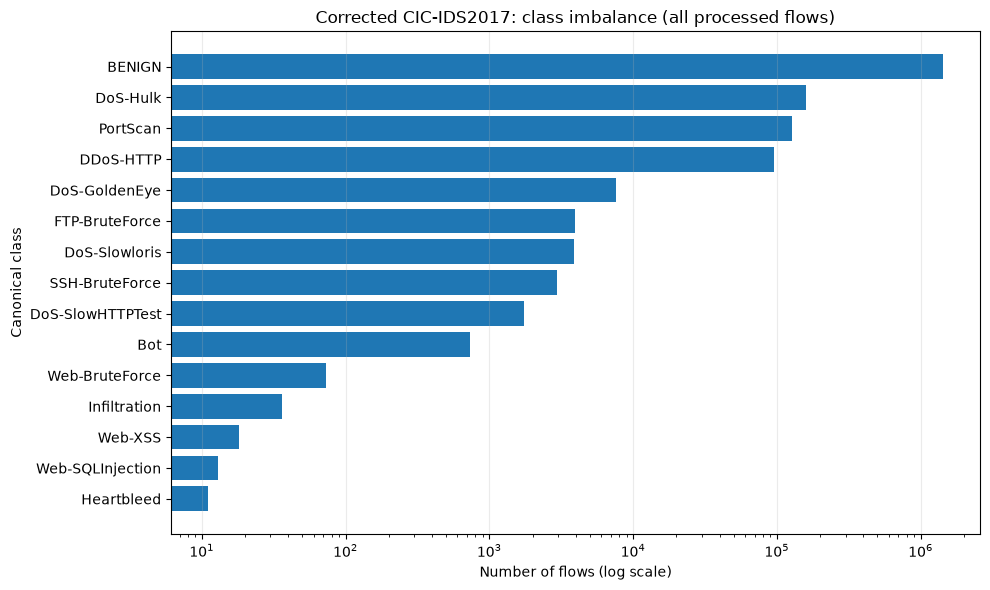

In [3]:
class_counts = meta[LABEL_COL].value_counts().sort_values(ascending=False)
class_table = class_counts.rename('flows').to_frame()
class_table['percent'] = class_table['flows'] / N * 100
class_table.index.name = 'class'
display(class_table.style.format({'flows': '{:,}', 'percent': '{:.5f}'}))
imbalance_ratio = class_counts.max() / class_counts.min()
print(f'Largest/smallest class: {imbalance_ratio:,.1f}:1 '
      f'({class_counts.idxmax()} / {class_counts.idxmin()})')
rare_names = ['Heartbleed', 'Infiltration', 'Web-SQLInjection']
display(class_table.reindex(rare_names))

fig, ax = plt.subplots(figsize=(10, 6))
ordered = class_counts.sort_values()
ax.barh(ordered.index.astype(str), ordered.values, color=BLUE)
ax.set_xscale('log')
ax.set_xlabel('Number of flows (log scale)')
ax.set_ylabel('Canonical class')
ax.set_title('Corrected CIC-IDS2017: class imbalance (all processed flows)')
ax.grid(axis='x', alpha=0.25)
fig.tight_layout()
save_figure(fig, 'class_distribution')


## 3. Flows per day/source file per class

Attack classes cluster in particular capture files, making randomly mixed flows an optimistic test when adjacent traffic shares the same capture conditions. The project's `temporal_split` orders flows **within each class** into earlier training, middle validation and later test portions, retaining rare classes where possible. This differs from a strict whole-day holdout: calendar ranges can overlap between classes, and performance within a known attack burst does not establish generalisation to new days or networks.


Label,BENIGN,DoS-Hulk,PortScan,DDoS-HTTP,DoS-GoldenEye,FTP-BruteForce,DoS-Slowloris,SSH-BruteForce,DoS-SlowHTTPTest,Bot,Web-BruteForce,Infiltration,Web-XSS,Web-SQLInjection,Heartbleed
source_file,,,,,,,,,,,,,,,
monday,"340,240",0,0,0,0,0,0,0,0,0,0,0,0,0,0
tuesday,"281,142",0,0,0,0,"3,972",0,"2,961",0,0,0,0,0,0,0
wednesday,"281,017","158,468",0,0,"7,567",0,"3,859",0,"1,740",0,0,0,0,0,11
thursday,"258,872",0,"36,811",0,0,0,0,0,0,0,73,36,18,13,0
friday,"273,306",0,"90,613","95,144",0,0,0,0,0,736,0,0,0,0,0


Label,BENIGN,DoS-Hulk,PortScan,DDoS-HTTP,DoS-GoldenEye,FTP-BruteForce,DoS-Slowloris,SSH-BruteForce,DoS-SlowHTTPTest,Bot,Web-BruteForce,Infiltration,Web-XSS,Web-SQLInjection,Heartbleed
source_file,,,,,,,,,,,,,,,
monday,23.7%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
tuesday,19.6%,0.0%,0.0%,0.0%,0.0%,100.0%,0.0%,100.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%
wednesday,19.6%,100.0%,0.0%,0.0%,100.0%,0.0%,100.0%,0.0%,100.0%,0.0%,0.0%,0.0%,0.0%,0.0%,100.0%
thursday,18.0%,0.0%,28.9%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,100.0%,100.0%,100.0%,100.0%,0.0%
friday,19.1%,0.0%,71.1%,100.0%,0.0%,0.0%,0.0%,0.0%,0.0%,100.0%,0.0%,0.0%,0.0%,0.0%,0.0%


13/15 classes occur in only one source file/date.


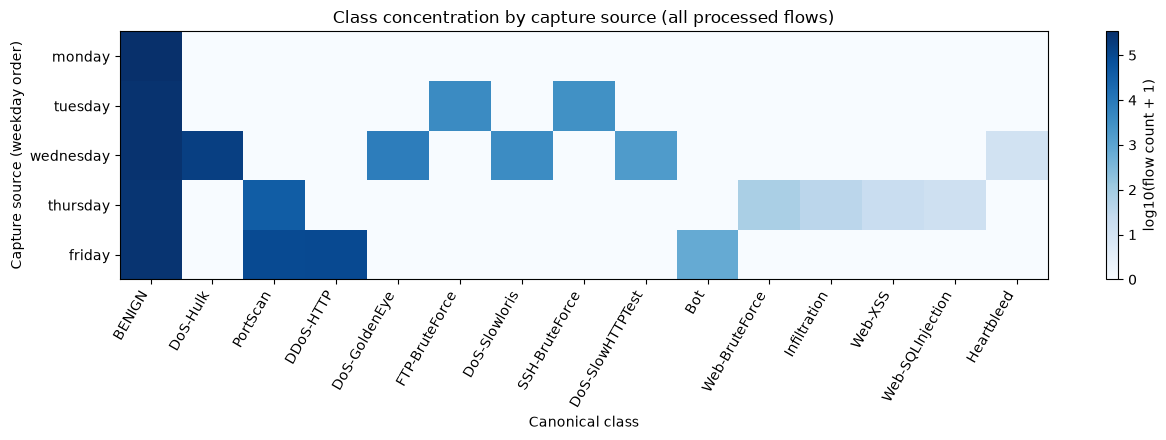

In [4]:
if 'source_file' in meta:
    capture = meta['source_file'].astype('string')
    weekday_order = ['monday', 'tuesday', 'wednesday', 'thursday', 'friday', 'saturday', 'sunday']
    def capture_order(name: str):
        lower = str(name).lower()
        rank = next((i for i, day in enumerate(weekday_order) if day in lower), 99)
        return rank, lower
    capture_ordered = sorted(capture.dropna().unique(), key=capture_order)
    capture_label = 'Capture source (weekday order)'
else:
    # Same mixed-format parsing convention as ids.data.temporal_split.
    timestamps = pd.to_datetime(meta['Timestamp'], errors='coerce', format='mixed')
    capture = timestamps.dt.strftime('%Y-%m-%d').fillna('Unparseable timestamp')
    capture_ordered = sorted(capture.unique())
    capture_label = 'Capture date'
    print('Unparseable timestamps:', int(timestamps.isna().sum()))
source_counts = pd.crosstab(capture.fillna('Missing source'), meta[LABEL_COL], dropna=False)
source_counts = source_counts.reindex(index=capture_ordered, columns=class_counts.index, fill_value=0)
assert int(source_counts.to_numpy().sum()) == N
source_share = source_counts.div(source_counts.sum(axis=0), axis=1) * 100
display(source_counts.style.format('{:,}').set_caption('Full-population flow counts'))
display(source_share.style.format('{:.1f}%').set_caption('Share of each class in each source'))
classes_one_source = source_counts.gt(0).sum(axis=0).eq(1)
print(f'{int(classes_one_source.sum())}/{len(class_counts)} classes occur in only one source file/date.')

fig, ax = plt.subplots(figsize=(13, 4.5))
im = ax.imshow(np.log10(source_counts.to_numpy() + 1), aspect='auto', cmap='Blues')
ax.set_xticks(range(len(source_counts.columns)), source_counts.columns, rotation=60, ha='right')
ax.set_yticks(range(len(source_counts.index)), source_counts.index)
ax.set_xlabel('Canonical class')
ax.set_ylabel(capture_label)
ax.set_title('Class concentration by capture source (all processed flows)')
fig.colorbar(im, ax=ax, label='log10(flow count + 1)')
fig.tight_layout()
save_figure(fig, 'source_class')


## 4. Feature quality

The following statistics scan all rows one projected numeric column at a time, keeping the full feature matrix out of memory. A constant feature has one distinct finite value; a near-constant feature has a modal share of at least 99% but is not constant, and heavy skew is defined as absolute sample skewness greater than 5. High zero share may describe legitimate protocol behaviour, so sparse features should be checked against class-specific utility before removal; transformations and drop decisions must be fitted on training data.


Constant features: []
Near-constant features (>=99% modal value; excludes constants): ['Fwd URG Flags', 'Bwd URG Flags', 'URG Flag Count', 'CWR Flag Count', 'ECE Flag Count', 'Subflow Bwd Packets', 'ICMP Code', 'ICMP Type']
Heavy-skew features (|skew| > 5): 56 / 83


,invalid_share,zero_share,unique_finite,mode_share,variance,skew,discrete_low_cardinality
feature,,,,,,,
Bwd URG Flags,0.00%,100.00%,2,100.00%,2.178e-06,1355.212,True
Subflow Bwd Packets,0.00%,100.00%,2,100.00%,1.797e-05,235.906,True
Fwd URG Flags,0.00%,99.99%,5,99.99%,0.003069,193.733,True
URG Flag Count,0.00%,99.99%,5,99.99%,0.003071,193.553,True
ECE Flag Count,0.00%,99.96%,5,99.96%,0.003499,157.961,True
CWR Flag Count,0.00%,99.96%,9,99.96%,0.001082,246.290,True
Subflow Fwd Packets,0.00%,98.73%,2,98.73%,0.01255,8.698,True
Fwd Packet/Bulk Avg,0.00%,95.51%,98,95.51%,26.73,567.674,False
Fwd Bytes/Bulk Avg,0.00%,95.51%,4569,95.51%,8.055e+06,407.403,False


,skew,zero_share
feature,,
Bwd URG Flags,1355.211792,0.999999
Total Length of Fwd Packet,860.258183,0.108539
Fwd Packet/Bulk Avg,567.673679,0.955098
Fwd Bytes/Bulk Avg,407.402846,0.955098
Bwd Bytes/Bulk Avg,386.725400,0.841203
Fwd Act Data Pkts,381.308090,0.247522
Bwd Packet/Bulk Avg,354.749245,0.841203
Fwd PSH Flags,323.508228,0.569943
CWR Flag Count,246.290133,0.999584


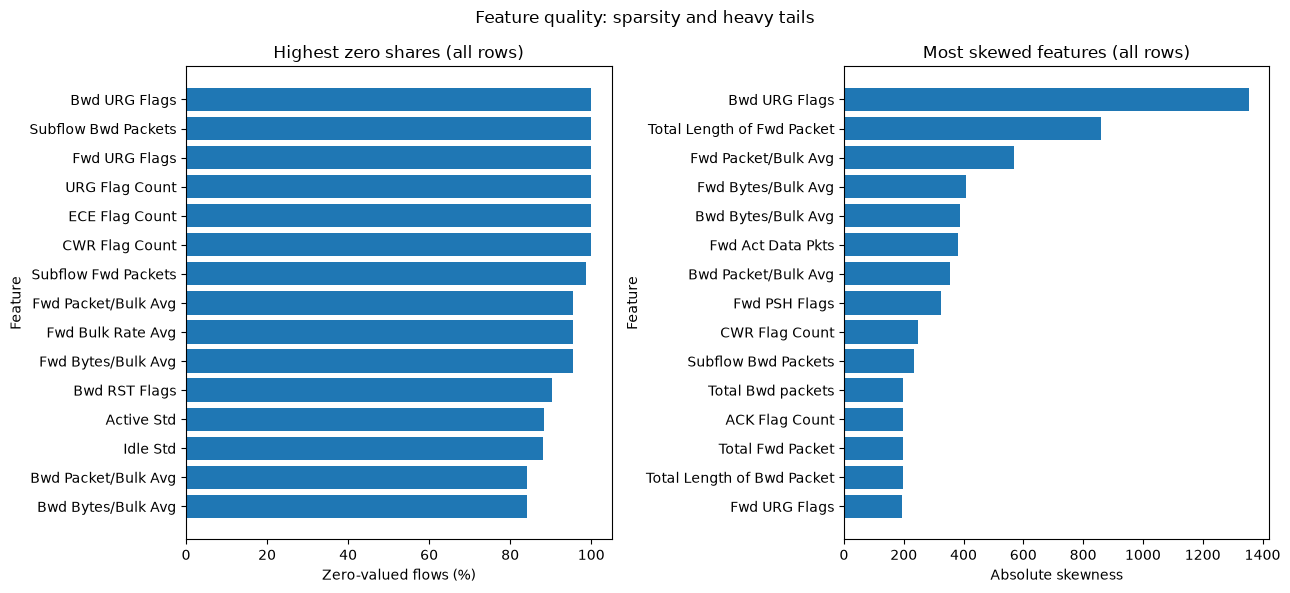

11548

In [5]:
quality_rows = []
for feature in FEATURES:
    series = pd.read_parquet(DATA, columns=[feature])[feature]
    values = series.to_numpy(dtype=np.float64)
    finite_mask = np.isfinite(values)
    finite = pd.Series(values[finite_mask], copy=False)
    frequencies = finite.value_counts()
    unique = len(frequencies)
    quality_rows.append({
        'feature': feature,
        'invalid_share': 1 - finite_mask.mean(),
        'zero_share': float(np.count_nonzero(values == 0) / N),
        'unique_finite': unique,
        'mode_share': float(frequencies.iloc[0] / N) if unique else np.nan,
        'variance': float(finite.var(ddof=1)),
        'skew': float(finite.skew()) if unique > 1 else np.nan,
        'discrete_low_cardinality': bool(unique <= 32 and np.equal(finite, np.floor(finite)).all()),
    })
    del series, values, finite_mask, finite, frequencies
quality = pd.DataFrame(quality_rows).set_index('feature')
constants = quality.index[quality['unique_finite'].eq(1)].tolist()
near_constants = quality.index[quality['mode_share'].ge(0.99) & quality['unique_finite'].gt(1)].tolist()
heavy_skew = quality.loc[quality['skew'].abs().gt(5)].sort_values('skew', key=abs, ascending=False)
assert quality['invalid_share'].max() == 0, 'Unexpected invalid values: rebuild processed input.'
print('Constant features:', constants)
print('Near-constant features (>=99% modal value; excludes constants):', near_constants)
print(f'Heavy-skew features (|skew| > 5): {len(heavy_skew)} / {len(FEATURES)}')
display(quality.sort_values('zero_share', ascending=False).style.format({
    'invalid_share': '{:.2%}', 'zero_share': '{:.2%}', 'mode_share': '{:.2%}',
    'variance': '{:.4g}', 'skew': '{:.3f}',
}))
display(heavy_skew[['skew', 'zero_share']])

fig, axes = plt.subplots(1, 2, figsize=(13, 6))
zero_top = quality['zero_share'].nlargest(15).sort_values()
axes[0].barh(zero_top.index, zero_top.values * 100, color=BLUE)
axes[0].set(xlabel='Zero-valued flows (%)', ylabel='Feature', title='Highest zero shares (all rows)', xlim=(0, 105))
skew_top = quality['skew'].abs().dropna().nlargest(15).sort_values()
axes[1].barh(skew_top.index, skew_top.values, color=BLUE)
axes[1].set(xlabel='Absolute skewness', ylabel='Feature', title='Most skewed features (all rows)')
fig.suptitle('Feature quality: sparsity and heavy tails')
fig.tight_layout()
save_figure(fig, 'feature_quality')
gc.collect()


## 5. Correlation

Spearman correlations use a seeded simple random sample of up to 20,000 flows to approximate the population mix without expensive all-row ranking. The heatmap shows the 30 features with highest **full-population variance in their original units**, a ranking influenced by measurement scale; the high-correlation pair table searches all non-constant features. Pairs with absolute rho above 0.95 are redundancy candidates rather than automatic drops, and their stability and model impact must be checked on training data.


clean() sample audit: 34,228 -> 34,228 (0 invalid/duplicate rows removed). This is not a population estimate.


Spearman sample: 20,000 flows; pairs with |rho| > 0.95: 67


,feature_1,feature_2,rho,abs_rho
0,Fwd URG Flags,URG Flag Count,1.000000,1.000000
1,Bwd Packet Length Mean,Bwd Segment Size Avg,1.000000,1.000000
2,Fwd Packet Length Mean,Fwd Segment Size Avg,1.000000,1.000000
3,ICMP Code,ICMP Type,1.000000,1.000000
4,Packet Length Mean,Average Packet Size,1.000000,1.000000
5,Packet Length Std,Packet Length Variance,1.000000,1.000000
6,CWR Flag Count,ECE Flag Count,1.000000,1.000000
7,Fwd Bytes/Bulk Avg,Fwd Packet/Bulk Avg,0.999764,0.999764
8,Fwd Bytes/Bulk Avg,Fwd Bulk Rate Avg,0.999594,0.999594
9,Fwd Packet/Bulk Avg,Fwd Bulk Rate Avg,0.999568,0.999568


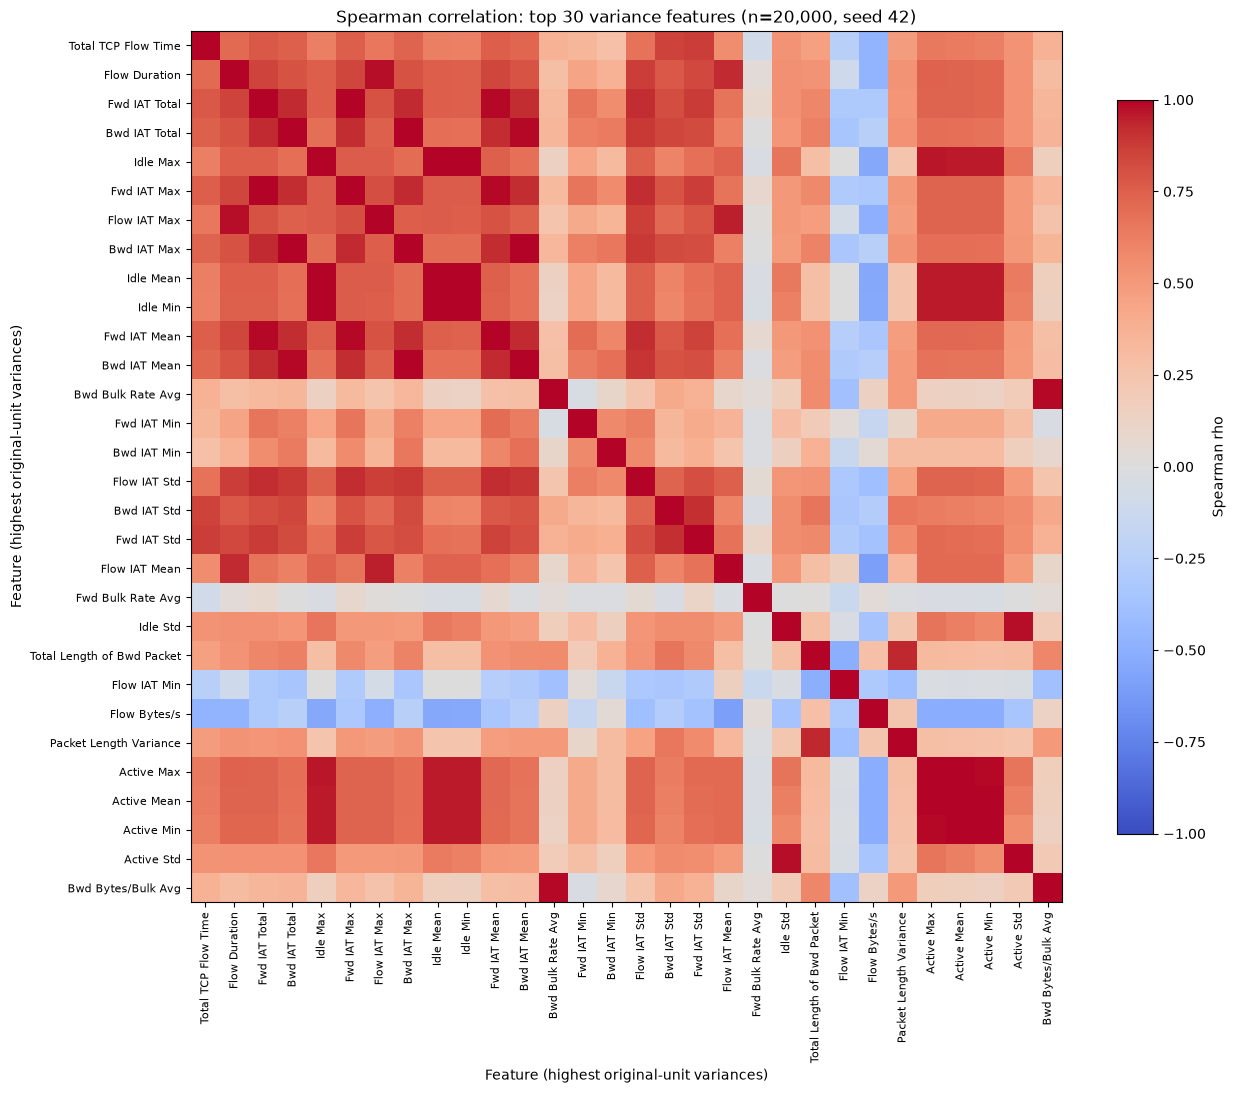

In [6]:
# Build both plot samples from row indices; no full numeric-frame read.
correlation_indices = meta.sample(n=min(20_000, N), random_state=SEED).index.to_numpy()
strata = meta[[LABEL_COL]].reset_index(names='_row')
stratified_indices = stratified_sample(strata, per_class=1_500, seed=SEED)['_row'].to_numpy()
selected_indices = np.unique(np.concatenate([correlation_indices, stratified_indices]))
sampled_columns = {}
for feature in FEATURES:
    series = pd.read_parquet(DATA, columns=[feature])[feature]
    sampled_columns[feature] = series.to_numpy()[selected_indices].copy()
    del series
sample = pd.DataFrame(sampled_columns, index=selected_indices)
del sampled_columns, strata
sample[LABEL_COL] = meta.loc[selected_indices, LABEL_COL]
# Reuse clean on all model features: a small audit, not global re-deduplication.
audit_clean = clean(sample)
sample_removed = len(sample) - len(audit_clean)
print(f'clean() sample audit: {len(sample):,} -> {len(audit_clean):,} '
      f'({sample_removed:,} invalid/duplicate rows removed). This is not a population estimate.')
del audit_clean

nonconstant = quality.index[quality['unique_finite'].gt(1)].tolist()
corr_frame = sample.loc[correlation_indices, nonconstant]
correlations = corr_frame.corr(method='spearman')
top_variance = quality.loc[nonconstant, 'variance'].nlargest(min(30, len(nonconstant))).index.tolist()
heatmap = correlations.loc[top_variance, top_variance]
pair_rows = []
for i, left in enumerate(nonconstant):
    for right in nonconstant[i + 1:]:
        rho = correlations.loc[left, right]
        if pd.notna(rho) and abs(rho) > 0.95:
            pair_rows.append({'feature_1': left, 'feature_2': right, 'rho': rho, 'abs_rho': abs(rho)})
high_pairs = pd.DataFrame(pair_rows, columns=['feature_1', 'feature_2', 'rho', 'abs_rho'])
high_pairs = high_pairs.sort_values('abs_rho', ascending=False).reset_index(drop=True)
print(f'Spearman sample: {len(corr_frame):,} flows; pairs with |rho| > 0.95: {len(high_pairs)}')
# Emit the complete list without pandas' default row truncation.
with pd.option_context('display.max_rows', None):
    display(high_pairs)

fig, ax = plt.subplots(figsize=(13, 12))
im = ax.imshow(heatmap, cmap='coolwarm', vmin=-1, vmax=1, aspect='equal')
ax.set_xticks(range(len(top_variance)), top_variance, rotation=90, fontsize=8)
ax.set_yticks(range(len(top_variance)), top_variance, fontsize=8)
ax.set_xlabel('Feature (highest original-unit variances)')
ax.set_ylabel('Feature (highest original-unit variances)')
ax.set_title(f'Spearman correlation: top {len(top_variance)} variance features '
             f'(n={len(corr_frame):,}, seed 42)')
fig.colorbar(im, ax=ax, label='Spearman rho', shrink=0.7)
fig.tight_layout()
save_figure(fig, 'spearman_correlation')


## 6. Separability

Mutual information ranks features against the binary attack-versus-BENIGN target on a stratified sample capped at 1,500 flows per canonical class, retaining tiny classes in full. This intentionally changes class proportions, so the ranking and binary box plots describe an attack-enriched diagnostic sample, not population prevalence or measured classifier performance. Signed-log transforms preserve negative sentinel values and compress heavy tails; PCA then standardises non-constant features on a second sample capped at 500 per class. PCA is unsupervised and two-dimensional overlap or separation cannot establish detection quality, especially for classes represented by only a handful of flows.


,population,MI_sample,sample_percent
class,,,
BENIGN,1434577,1500,10.426079
DoS-Hulk,158468,1500,10.426079
PortScan,127424,1500,10.426079
DDoS-HTTP,95144,1500,10.426079
DoS-GoldenEye,7567,1500,10.426079
FTP-BruteForce,3972,1500,10.426079
DoS-Slowloris,3859,1500,10.426079
SSH-BruteForce,2961,1500,10.426079
DoS-SlowHTTPTest,1740,1500,10.426079


MI sample: 14,387 rows; attack share 89.57%


,binary_mutual_information_nats
Total Length of Bwd Packet,0.280033
Bwd Segment Size Avg,0.276092
Bwd Packet Length Mean,0.275249
Dst Port,0.272392
Bwd Packet Length Max,0.267235
Packet Length Max,0.266352
Packet Length Variance,0.248479
Packet Length Std,0.247917
Bwd Header Length,0.241643
Total TCP Flow Time,0.234341


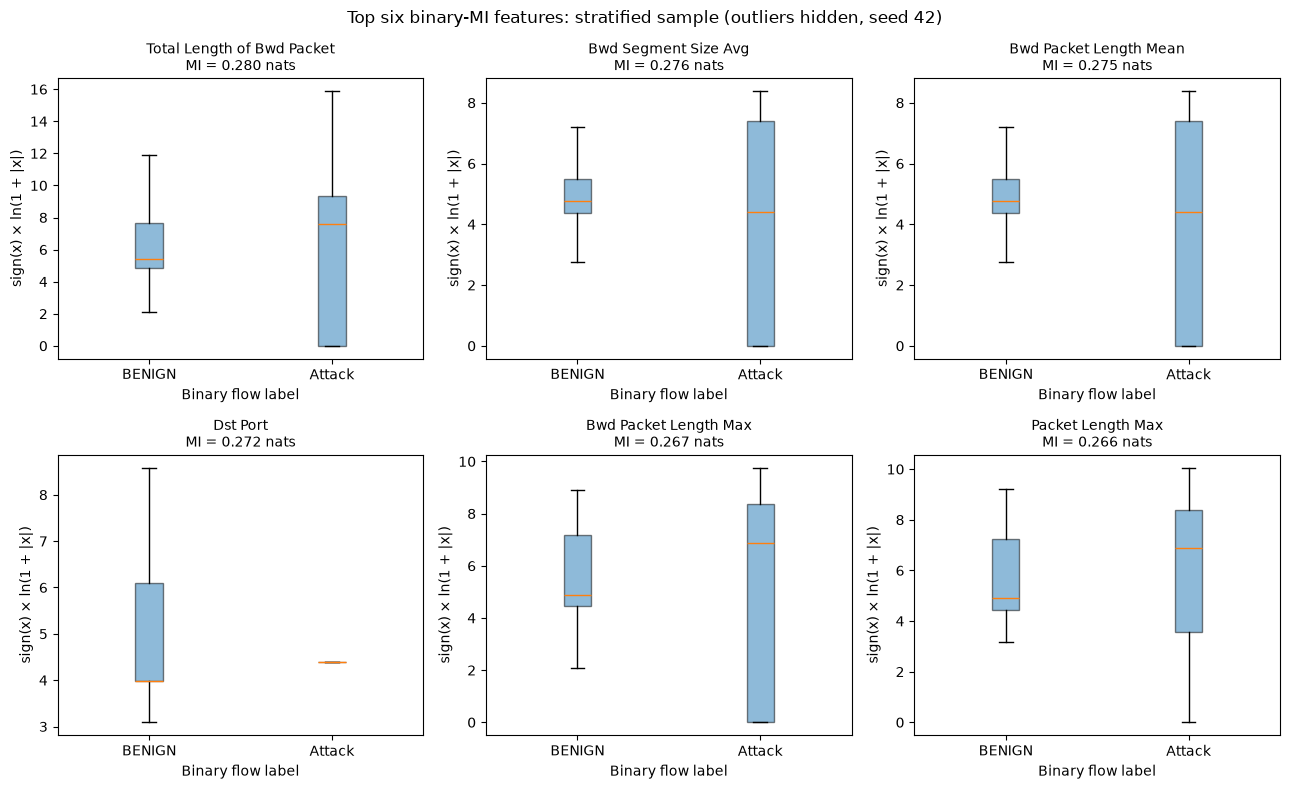

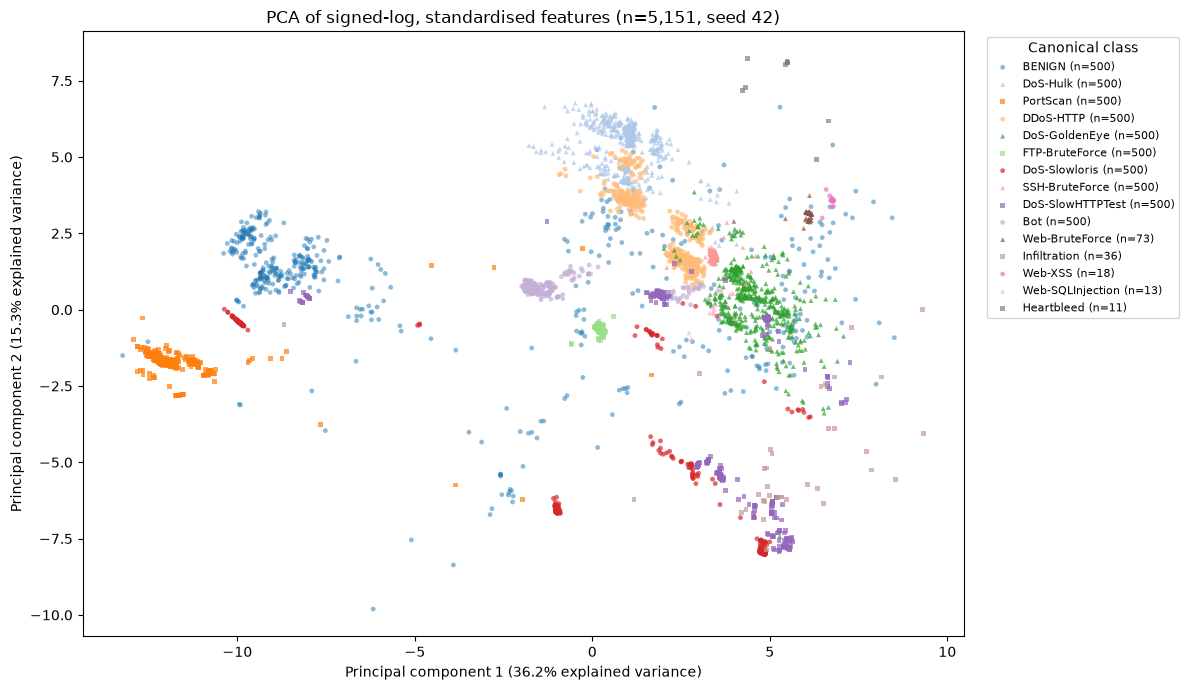

Two-component explained variance: 51.49%


In [7]:
separation = sample.loc[stratified_indices].copy()
sample_counts = separation[LABEL_COL].value_counts().reindex(class_counts.index)
sampling_table = class_table[['flows']].rename(columns={'flows': 'population'})
sampling_table['MI_sample'] = sample_counts
sampling_table['sample_percent'] = sample_counts / len(separation) * 100
display(sampling_table)

X_mi = separation[nonconstant].astype(np.float64)
y_binary = separation[LABEL_COL].ne(BENIGN).astype(int).to_numpy()
assert len(np.unique(y_binary)) == 2
# Scale continuous columns to reduce numerical sensitivity; mark small integer alphabets as discrete.
X_mi_scaled = StandardScaler().fit_transform(X_mi)
discrete_mask = quality.loc[nonconstant, 'discrete_low_cardinality'].to_numpy(dtype=bool)
# Keep discrete alphabets integer-valued: scaling them triggers classification warnings.
X_mi_scaled[:, discrete_mask] = X_mi.to_numpy()[:, discrete_mask]
mi = mutual_info_classif(X_mi_scaled, y_binary, discrete_features=discrete_mask,
                        random_state=SEED, n_neighbors=3)
mi_scores = pd.Series(mi, index=nonconstant, name='binary_mutual_information_nats').sort_values(ascending=False)
selected_six = mi_scores.head(6).index.tolist()
print(f'MI sample: {len(separation):,} rows; attack share {y_binary.mean():.2%}')
display(mi_scores.head(15).to_frame())

fig, axes = plt.subplots(2, 3, figsize=(13, 8))
for ax, feature in zip(axes.flat, selected_six):
    values = separation[feature].to_numpy(dtype=np.float64)
    transformed = np.sign(values) * np.log1p(np.abs(values))
    artists = ax.boxplot([transformed[y_binary == 0], transformed[y_binary == 1]],
                        tick_labels=['BENIGN', 'Attack'], patch_artist=True, showfliers=False)
    for patch in artists['boxes']:
        patch.set_facecolor(BLUE)
        patch.set_alpha(0.5)
    ax.set_title(f'{feature}\nMI = {mi_scores[feature]:.3f} nats', fontsize=10)
    ax.set_xlabel('Binary flow label')
    ax.set_ylabel('sign(x) × ln(1 + |x|)')
fig.suptitle('Top six binary-MI features: stratified sample (outliers hidden, seed 42)')
fig.tight_layout()
save_figure(fig, 'separability_boxplots')

pca_frame = stratified_sample(separation, per_class=500, seed=SEED)
pca_values = pca_frame[nonconstant].to_numpy(dtype=np.float64)
pca_values = np.sign(pca_values) * np.log1p(np.abs(pca_values))
pca_values = StandardScaler().fit_transform(pca_values)
pca = PCA(n_components=2, svd_solver='full', random_state=SEED)
coordinates = pca.fit_transform(pca_values)
pca_counts = pca_frame[LABEL_COL].value_counts().reindex(class_counts.index)
fig, ax = plt.subplots(figsize=(12, 7))
colors = plt.get_cmap('tab20')
for i, label in enumerate(class_counts.index):
    mask = pca_frame[LABEL_COL].eq(label).to_numpy()
    ax.scatter(coordinates[mask, 0], coordinates[mask, 1], s=12,
               alpha=0.5 if label == BENIGN else 0.7, color=colors(i),
               label=f'{label} (n={int(mask.sum()):,})', edgecolors='none',
               marker=['o', '^', 's'][i % 3])
ax.set_xlabel(f'Principal component 1 ({pca.explained_variance_ratio_[0]:.1%} explained variance)')
ax.set_ylabel(f'Principal component 2 ({pca.explained_variance_ratio_[1]:.1%} explained variance)')
ax.set_title(f'PCA of signed-log, standardised features (n={len(pca_frame):,}, seed 42)')
ax.legend(title='Canonical class', bbox_to_anchor=(1.02, 1), loc='upper left', fontsize=8)
fig.tight_layout()
save_figure(fig, 'pca_classes')
print(f'Two-component explained variance: {pca.explained_variance_ratio_.sum():.2%}')


## 7. Key findings for the report

The bullets below are generated from this run so the report can trace every numerical claim to the current input. They connect descriptive evidence to design decisions, while leaving model evaluation and training-only feature selection to subsequent experiments.


In [8]:
rare_summary = ', '.join(f'{label}: {int(class_counts.get(label, 0)):,}' for label in rare_names)
removal_summary = (f'{rows_removed:,} fewer rows than the historical raw profile'
                   if rows_removed is not None else 'no historical raw removal count available')
findings = [
    f'**Provenance and deduplication:** {N:,} processed flows and {len(FEATURES)} features; '
    f'{removal_summary}. Every feature vector is unique after global deduplication, so train, validation '
    'and test splits cannot share a vector.',
    f'**Class weights and caps:** the largest/smallest ratio is {imbalance_ratio:,.1f}:1. '
    'Cap dominant training classes and compare class weighting using validation macro F1; '
    'retain rare training examples and keep evaluation at its natural prevalence.',
    f'**Rare-class evaluation:** {rare_summary}. Report macro and per-class precision, recall '
    'and F1, support, benign false-positive rate and a confusion matrix; flag uncertainty '
    'from tiny supports and avoid accuracy-only conclusions.',
    f'**Chronology:** {int(classes_one_source.sum())}/{len(class_counts)} classes occur in '
    'one capture source/date. Use the existing per-class chronological split to test later '
    'flows, disclose overlapping calendar windows, and use cross-dataset/lab evaluation '
    'to assess transfer beyond known capture conditions.',
    f'**Identifiers:** {len(excluded)} stored columns are excluded by feature_columns(). '
    'Keep IPs, source ports, timestamps, source files and labels out of model inputs; '
    'check destination-port dependence separately because it remains a candidate feature.',
    f'**Feature quality:** {len(constants)} constant, {len(near_constants)} near-constant '
    f'(>=99% modal share), and {len(heavy_skew)} heavily skewed (|skew| > 5) features. '
    'Fit constant removal and any log/scale transforms on training data; do not discard '
    'zero-heavy protocol indicators solely because they are sparse.',
    f'**Redundancy:** {len(high_pairs)} sampled feature pairs have |Spearman rho| > 0.95. '
    'Compare keeping one representative per correlated group, checking validation macro F1 '
    'and explanation stability before changing the training feature set.',
    f'**Separability limits:** {selected_six[0]} has the highest binary MI in the capped '
    f'sample; two PCA components explain {pca.explained_variance_ratio_.sum():.1%} of '
    'transformed sample variance. These diagnostic views motivate experiments and do not '
    'measure performance or prove rare attacks are reliably separable.',
]
display(Markdown('\n'.join('- ' + finding for finding in findings)))
elapsed = time.perf_counter() - START
print(f'Completed in {elapsed:.1f} seconds ({elapsed / 60:.2f} minutes).')
print(f'{len(SAVED_FIGURES)} PNG figures saved at 150 dpi:')
print('\n'.join('  notebooks/figures/' + name for name in SAVED_FIGURES))
assert len(SAVED_FIGURES) == 6
assert all((FIGURES / name).is_file() for name in SAVED_FIGURES)


- **Provenance and deduplication:** 1,836,599 processed flows and 83 features; 263,377 fewer rows than the historical raw profile. Every feature vector is unique after global deduplication, so train, validation and test splits cannot share a vector.
- **Class weights and caps:** the largest/smallest ratio is 130,416.1:1. Cap dominant training classes and compare class weighting using validation macro F1; retain rare training examples and keep evaluation at its natural prevalence.
- **Rare-class evaluation:** Heartbleed: 11, Infiltration: 36, Web-SQLInjection: 13. Report macro and per-class precision, recall and F1, support, benign false-positive rate and a confusion matrix; flag uncertainty from tiny supports and avoid accuracy-only conclusions.
- **Chronology:** 13/15 classes occur in one capture source/date. Use the existing per-class chronological split to test later flows, disclose overlapping calendar windows, and use cross-dataset/lab evaluation to assess transfer beyond known capture conditions.
- **Identifiers:** 6 stored columns are excluded by feature_columns(). Keep IPs, source ports, timestamps, source files and labels out of model inputs; check destination-port dependence separately because it remains a candidate feature.
- **Feature quality:** 0 constant, 8 near-constant (>=99% modal share), and 56 heavily skewed (|skew| > 5) features. Fit constant removal and any log/scale transforms on training data; do not discard zero-heavy protocol indicators solely because they are sparse.
- **Redundancy:** 67 sampled feature pairs have |Spearman rho| > 0.95. Compare keeping one representative per correlated group, checking validation macro F1 and explanation stability before changing the training feature set.
- **Separability limits:** Total Length of Bwd Packet has the highest binary MI in the capped sample; two PCA components explain 51.5% of transformed sample variance. These diagnostic views motivate experiments and do not measure performance or prove rare attacks are reliably separable.

Completed in 42.8 seconds (0.71 minutes).
6 PNG figures saved at 150 dpi:
  notebooks/figures/eda_class_distribution.png
  notebooks/figures/eda_source_class.png
  notebooks/figures/eda_feature_quality.png
  notebooks/figures/eda_spearman_correlation.png
  notebooks/figures/eda_separability_boxplots.png
  notebooks/figures/eda_pca_classes.png
